In [3]:
import numpy as np
import perceval as pcvl
from qiskit.quantum_info import Pauli, PauliList, Statevector
from qlass.quantum_chemistry.hamiltonians import transformation_Hmatrix_Hqubit, sparsepauliop_dictionary
from qlass.vqe.ansatz import Bitstring_initial_states
from qlass.vqe import VQE
from qlass.vqe.ansatz import list_of_ones
from qlass.utils import photon_to_qubit_unitary
from qiskit.circuit.library import n_local
from perceval.algorithm import Sampler
from qiskit import QuantumCircuit, transpile
from perceval.converters import QiskitConverter
from perceval.components import catalog
from perceval.simulators import Simulator
from perceval import BasicState

import warnings
warnings.filterwarnings('ignore')



/home/arajamani/.local/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/arajamani/.local/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


In [4]:
def circuit(nqubit, n_states, lp, layers=1):
    initial_circuits = []

    if nqubit is None:
        num_qubits = 2
    else:
        num_qubits = nqubit
    for _i in range(n_states):
        initial_circuits += [QuantumCircuit(num_qubits)]
    """Initial states"""
    for state in range(n_states):  # binarystring representation of the integer
        for i in list_of_ones(state, num_qubits):
            initial_circuits[state].x(i)

    circuits = []
    for state in range(n_states):
        ansatz = n_local(
            num_qubits=num_qubits,
            rotation_blocks="ry",
            entanglement_blocks="cx",
            entanglement="linear",
            reps=layers,
            insert_barriers=False,
        )
        # Prepend the initial state
        circuit = QuantumCircuit(num_qubits)
        circuit.compose(initial_circuits[state], inplace=True)
        circuit.compose(ansatz, inplace=True)
        circuits.append(circuit)

    """Assign parameters"""
    intial_states = []
    for c in range(len(initial_circuits)):
        sv = Statevector.from_instruction(initial_circuits[c])
        index = list(sv.data).index(1 + 0j)  # position of the "1"
        bitstring = format(index, f"0{sv.num_qubits}b")
        bits_list = [int(b) for b in bitstring]
        intial_states.append(pcvl.LogicalState(bits_list))

    circuits = [c.assign_parameters(lp) for c in circuits]
    ansatz_transpiled = [
        transpile(c, basis_gates=["u3", "cx"], optimization_level=3) for c in circuits
    ]
    q_converter = QiskitConverter(backend_name="SLOS")
    processors = [q_converter.convert(at) for at in ansatz_transpiled]

    p_processors = [p.with_input(input_state=ist) for p, ist in zip(processors, intial_states, strict=False)]


    return processors, circuits

In [5]:
params = [0.1, 0.2, 0.3, 0.4]

pcvl_processors, qiskit_circuit = circuit(2, 2, layers=1, lp=params)

"Qiskit circuit overlap"
qubit_psi0 = Statevector.from_instruction(qiskit_circuit[0])
qubit_psi1 = Statevector.from_instruction(qiskit_circuit[1])

overlap_qiskit_circuit = np.real(np.vdot(qubit_psi0, qubit_psi1))

print(f"printing overlap from qiskit circuits: {overlap_qiskit_circuit}")

psi_0 = pcvl_processors[0].linear_circuit().compute_unitary(use_symbolic=False)
psi_1 = pcvl_processors[1].linear_circuit().compute_unitary(use_symbolic=False)

v0 = psi_0.flatten()
v1 = psi_1.flatten()
v0 /= np.linalg.norm(v0)
v1 /= np.linalg.norm(v1)

print(f"printing overlap from perceval processors using photonic unitary: {np.real(np.vdot(v0, v1))}")

qpsi_0 = photon_to_qubit_unitary(psi_0)
qpsi_1 = photon_to_qubit_unitary(psi_1)

pv0 = qpsi_0.flatten()
pv1 = qpsi_1.flatten()
pv0 /= np.linalg.norm(pv0)
pv1 /= np.linalg.norm(pv1)

print(f"printing overlap from perceval processors using qubit unitary: {np.real(np.vdot(pv0, pv1))}")
print(qiskit_circuit[0])
print(qiskit_circuit[1])

printing overlap from qiskit circuits: 9.949220193311344e-18
printing overlap from perceval processors using photonic unitary: 0.6666666666666665
printing overlap from perceval processors using qubit unitary: -3.543504908936004e-17
     ┌─────────┐     ┌─────────┐
q_0: ┤ Ry(0.1) ├──■──┤ Ry(0.3) ├
     ├─────────┤┌─┴─┐├─────────┤
q_1: ┤ Ry(0.2) ├┤ X ├┤ Ry(0.4) ├
     └─────────┘└───┘└─────────┘
        ┌───┐   ┌─────────┐     ┌─────────┐
q_0: ───┤ X ├───┤ Ry(0.1) ├──■──┤ Ry(0.3) ├
     ┌──┴───┴──┐└─────────┘┌─┴─┐├─────────┤
q_1: ┤ Ry(0.2) ├───────────┤ X ├┤ Ry(0.4) ├
     └─────────┘           └───┘└─────────┘


printing ciruit


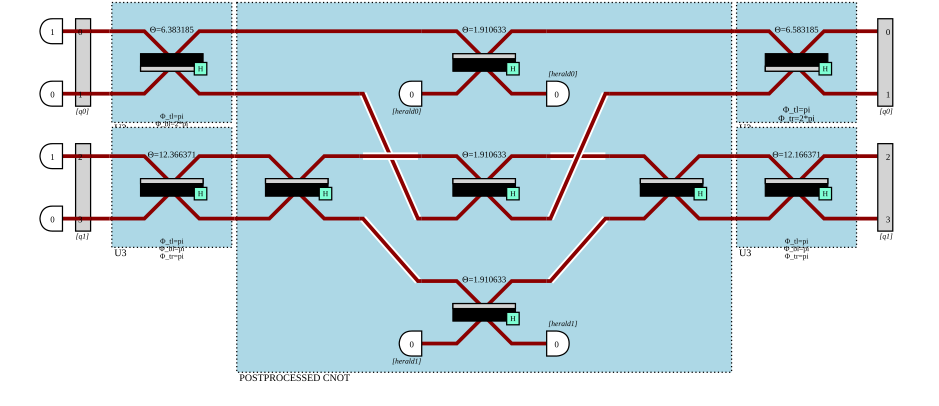

In [6]:
"Building the circuit matrix by Hand"
print("printing ciruit")
pcvl.pdisplay(pcvl_processors[0], recursive=True)


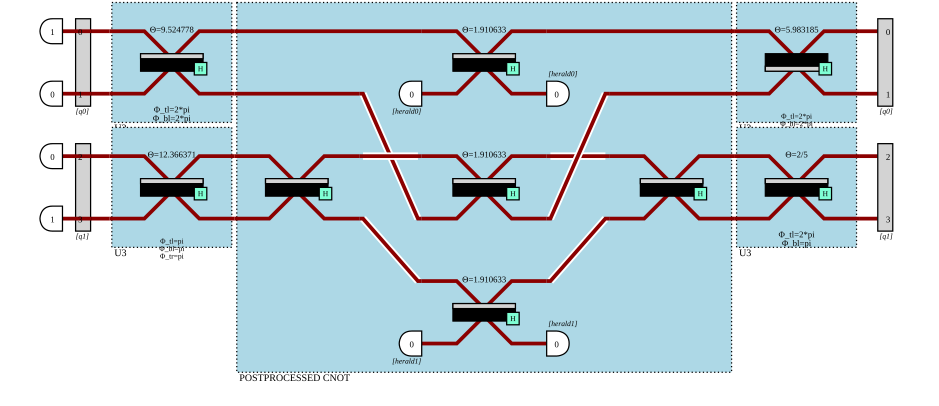

In [7]:
pcvl.pdisplay(pcvl_processors[1], recursive=True)

In [8]:
   
def U(theta, tl, bl, tr, br):
    """
            [[exp(i*(tl + tr)) * cos(theta/2),    exp(i*(bl + tr)) * sin(theta/2)],
            [exp(i*(tl + br)) * sin(theta/2),   exp(i*(br + bl)) * -cos(theta/2)]]
    """
    return np.array([[np.exp(1j*(tl+tr)) * np.cos(theta/2), np.exp(1j*(bl+tr)) * np.sin(theta/2)], [
        np.exp(1j*(tl+br)) * np.sin(theta/2), np.exp(1j*(br+bl)) * -np.cos(theta/2)]], dtype=complex)


op_CX = np.array([[1, 0, 0, 0],
             [0, 1, 0, 0],
             [0, 0, 0, 1],
             [0, 0, 1, 0]], dtype=np.cdouble) # Considering it as unitary for CNOT

In [9]:
circuit_matrix_1 = (np.kron(U(theta=.857282, tl=2*np.pi, bl=np.pi, tr=2*np.pi, br=0), U(theta=6.315544, tl=np.pi, bl=2*np.pi, tr=0, br=0))
                    @ op_CX
                    @ np.kron(U(theta=5.405635, tl=2*np.pi, bl=2*np.pi, tr=np.pi, br=0), U(theta=11.649642, tl=np.pi, bl=np.pi, tr=np.pi, br=0)))



circuit_matrix_2 = (np.kron(U(theta=2.284311, tl=np.pi, bl=0, tr=np.pi, br=0), U(theta=6.250827, tl=2*np.pi, bl=2*np.pi, tr=np.pi, br=0))
                    @ op_CX
                    @ np.kron(U(theta=0.87755, tl=2*np.pi, bl=np.pi, tr=2*np.pi, br=0), U(theta=5.366457, tl=2*np.pi, bl=2*np.pi, tr=np.pi, br=0)))

In [10]:
print("Printing overlap by calculating using the matrix form U: ",np.real(np.vdot(circuit_matrix_1, circuit_matrix_2)/4))

Printing overlap by calculating using the matrix form U:  -5.5511151231257685e-17
